This notebook builds and evaluates a bag-of-words fact checker. Each **fact** is an atomic claim extracted from a ChatGPT-generated biography, paired with Wikipedia **passages** retrieved by BM25. The goal is to predict **S** (supported) or **NS** (not supported) from lexical overlap alone.

**Approach:** preprocess text -> compute an overlap score between the fact and its evidence -> predict S if the score is more than equal to a tuned threshold θ.

**Result:** IDF-weighted recall at passage level reaches **81.9%** dev accuracy (θ = 0.605), above the 75% target.

In [2]:
!pip install scikit-learn

## 1. Imports

In [ ]:
import json
import re
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from pathlib import Path
from collections import Counter
from math import log, sqrt
import csv

import numpy as np
from nltk.stem import PorterStemmer
from spacy.lang.en.stop_words import STOP_WORDS
from sklearn.metrics import classification_report

## 2. Data Loading

Two files are used:
- `dev_labeled_ChatGPT.jsonl`: These are 31 ChatGPT biographies, each split into sentences with human-annotated atomic facts and labels.
- `passages_bm25_ChatGPT_humfacts.jsonl`: for each fact, the Wikipedia passages retrieved by BM25 from the subject's page.

In [4]:
# define data directory and check for required files
DATA_DIR = Path("../../data").resolve()
dev_file = DATA_DIR / "dev_labeled_ChatGPT.jsonl"
passages_file = DATA_DIR / "passages_bm25_ChatGPT_humfacts.jsonl"

In [5]:
def read_jsonl(file_path):
    """Read a JSON Lines file into a list of dictionaries."""
    records = []

    with open(file_path, "r", encoding="utf-8") as file:
        for line_number, line in enumerate(file, start=1):
            if not line.strip():
                continue

            try:
                records.append(json.loads(line))
            except json.JSONDecodeError as exc:
                raise ValueError(
                    f"Invalid JSON in {file_path}, line {line_number}"
                ) from exc

    return records

In [6]:
# Load the development and passage data
dev_data = read_jsonl(dev_file)
passages_data = read_jsonl(passages_file)


# Display information about the loaded data
print(f"Loaded {len(dev_data)} development records.")
print(f"Loaded {len(passages_data)} passage records.")

Loaded 31 development records.
Loaded 5427 passage records.


In [7]:
# Display keys and example records
print("Development record keys:")
if dev_data:
    print(list(dev_data[0].keys()))

print("\nPassage record keys:")
if passages_data:
    print(list(passages_data[0].keys()))

# Dsplay example records
if dev_data:
    print("\nExample development record:")
    print(json.dumps(dev_data[0], indent=2, ensure_ascii=False)[:2500])

# Display example passage record
if passages_data:
    print("\nExample passage record:")
    print(json.dumps(passages_data[0], indent=2, ensure_ascii=False)[:2500])

Development record keys:
['input', 'output', 'topic', 'cat', 'annotations']

Passage record keys:
['name', 'sent', 'passages']

Example development record:
{
  "input": "Question: Tell me a bio of Marianne McAndrew.",
  "output": "Marianne McAndrew is an American actress and singer, born on November 21, 1942, in Cleveland, Ohio. She began her acting career in the late 1960s, appearing in various television shows and films. Her notable film appearances include the role of Irene Molloy in the 1969 film adaptation of the musical \"Hello, Dolly!\", and as Princess Zareta in the 1976 film \"The Blue Bird\". She also had recurring roles on popular television shows such as \"The Love Boat\" and \"Fantasy Island\". In addition to her acting career, McAndrew was a trained singer and performed in various stage productions, including the Broadway production of \"The King and I\". She retired from acting in the 1990s and currently resides in California.",
  "topic": "Marianne McAndrew",
  "cat": [

## 3. Label Mapping and Example Construction

Each fact will have one of three human labels:
- **S** (Supported): the fact is backed by Wikipedia.
- **NS** (Not Supported): the fact is false or not stated.
- **IR** (Irrelevant): the fact is not about the subject. Either ChatGPT confused them with someone else (e.g. *Fernandinho* in the bio of *Fernando*), or it's general knowledge (e.g. *"Cleveland is in Ohio."*). In other words, it's like a false positive.

Facts are matched to passages by exact sentence text; all 221 facts matched.

In [ ]:
# Binary mapping used in the earlier results:
# S = supported
# NS = not supported
# IR = irrelevant (treated as unsupported for this experiment)

RAW_LABEL_MAP = {
    "S": 1,
    "NS": 0,
    "IR": 0,
}

# Build a lookup from fact text -> its retrieved Wikipedia passages.
fact_to_passage = {}

# Loop through every record in the passages dataset.
for record in passages_data:
    # extract the fact text and its associated passages
    # extracting atomic fact (an individual statement to be checked independently)
    fact_text = record.get("sent")
    passages = record.get("passages") or []

    # checks that the fact is text.
    if isinstance(fact_text, str):
        # store the fact and its passages in the dictionary.
        fact_to_passage[fact_text] = passages

In [9]:
# store the processed examples in a list
examples = []

# facts that have no matching passage record.
missing_passage_facts = 0
# facts with missing text or labels.
missing_label_facts = 0
# facts with labels outside S, NS and IR.
unrecognized_label_facts = 0
observed_labels = Counter()

# Loop through every record in the development dataset
for record in dev_data:
    annotations = record.get("annotations") or []

    # If annotations arrive as a single dictionary instead of a list, this wraps the dictionary in a list.
    if isinstance(annotations, dict):
        annotations = [annotations]

    # Each ChatGPT bio is split into sentences; each sentences has a list of
    # human-written atomic facts, each with its own S/NS/IR label.
    # We only use the human facts (non model-extracted ones) to avoid.
    # errors from the fact-extraction step.
    for sentence_annotation in annotations:

        # An atomic fact is a small, individual claim that can be checked independently.
        atomic_facts = (
            sentence_annotation.get("human-atomic-facts") or []
        )

        for fact in atomic_facts:
            # Loops through each atomic fact and retrieves its text and original label.
            fact_text = fact.get("text")
            raw_label = fact.get("label")

            if not fact_text or raw_label is None:
                missing_label_facts += 1
                # Skip that fact.
                continue

            label = str(raw_label).strip().upper()
            observed_labels[label] += 1

            if label not in RAW_LABEL_MAP:
                unrecognized_label_facts += 1
                continue

            if fact_text not in fact_to_passage:
                missing_passage_facts += 1
                continue

            # Retrieves the passages associated with the fact.
            passages = fact_to_passage[fact_text] or []

            # 1 = supported, 0 = not supported (NS and IR),
            # matching how factchecking_main.py evaluates.
            examples.append({
                "fact": fact_text,
                "passages": passages,
                "label": label,
                # Here, gold means the human-provided reference answer, not a prediction from the algorithm.
                "gold_binary": RAW_LABEL_MAP[label],
            })

In [10]:
# Displays which labels appeared, how many times they appeared, 
# and how many examples survived preprocessing.
print("Labels found:", sorted(observed_labels.keys()))
print("Label counts:", dict(observed_labels))
print(f"Usable examples: {len(examples)}")
print(f"Missing passage matches: {missing_passage_facts}")
print(f"Missing text/label records: {missing_label_facts}")
print(f"Unrecognized labels skipped: {unrecognized_label_facts}")

# Displays how many records were skipped for each reason.
if not examples:
    raise ValueError(
        "No usable examples were constructed. Inspect the JSONL schemas "
        "and confirm that fact text matches the passage records."
    )

Labels found: ['IR', 'NS', 'S']
Label counts: {'NS': 93, 'S': 112, 'IR': 16}
Usable examples: 221
Missing passage matches: 0
Missing text/label records: 0
Unrecognized labels skipped: 0


## 4. Preprocessing: Stopwords and Stemming
**Stopwords:** Used spaCy's English list, since it needs no download and so also works in `factcheck.py`. So, words like *the, was, also, has* appear in almost every passage and inflate overlap for unsupported facts.

**Negations are kept** (*no, not, nor, never, none, n't*). Removing them would make *"X did not win"* look identical to *"X won"*.

**Stemming:** the Porter stemmer reduces morphological variants (*acting, acted, acts -> act*) to the same token so they still count as overlap.

The first cell holds the original hand-written stoplist, kept for comparison. The spaCy list in the second cell overrides it.

In [ ]:
# Creates a stemming tool that reduces words to their stems.
stemmer = PorterStemmer()

# Stopwords are common words that don't contribute much to identifying a fact
STOPWORDS = set("""
a an the and or but if then else when while
is am are was were be been being
to of in on at by for from with as
it its this that these those
he she they them their we our you your
i me my
""".split())

In [12]:
# Use spaCy's English stopword list. 
# Stopwords like "the", "was", "also" appear in almost
# every passage and inflate overlap for unsupported facts.
# Negation words are KEPT: removing "not" would make
# "X did not win" look identical to "X won".
NEGATION_WORDS = {"no", "not", "nor", "never", "none", "n't"}
STOPWORDS = set(STOP_WORDS) - NEGATION_WORDS

## 5. Tokenization, N-grams and Sentence Splitting

Tokenization steps: lowercase -> strip `<s>` tags -> replace punctuation with spaces -> split on whitespace -> remove stopwords -> stem.

Digits are kept, because years and dates (e.g. *1942*) are normally the exact detail that can decide whether a biography fact is true.

Passages can be scored **whole** (passage level) or **split into sentences** on `.`, `!` or `?` (sentence level). Both are compared in the ablation study.

In [ ]:
def tokenize(
    text,
    lower=True,
    remove_stop=True,
    stem=True,
):
    """Clean and tokenize text with configurable preprocessing."""

    if not isinstance(text, str):
        text = ""

    if lower:
        text = text.lower()

    # Remove HTML-like tags.
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove punctuation while preserving letters, digits and whitespace.
    # Digits are kept on purpose: years and dates ("1942") are often the
    # exact detail that decides whether a biography fact is supported.
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)

    # Splits the cleaned text into words.
    tokens = text.split()

    if remove_stop:
        tokens = [
            token for token in tokens
            if token not in STOPWORDS
        ]

    # Reduces each remaining word to its stem.
    if stem:
        tokens = [
            stemmer.stem(token)
            for token in tokens
        ]

    return tokens

# An n-gram is a sequence of n consecutive words.
# creates unigrams and bigrams.
# unigrams identify individual matching words, while bigrams identify matching word pairs
def make_ngrams(tokens, ngram_range=(1, 2)):
    """Generate word n-grams within the requested inclusive range."""

    min_n, max_n = ngram_range
    features = []

    # Loop through each n in the specified range to create n-grams.
    for n in range(min_n, max_n + 1):
        # Moves a window across the tokens to find each sequence of length n.
        for start in range(len(tokens) - n + 1):
            features.append(
                "_".join(tokens[start:start + n])
            )

    return features


# for both cases if string or dictionary
def get_passage_text(passage):
    """Support passage records stored as dictionaries or strings."""

    if isinstance(passage, str):
        return passage

    if isinstance(passage, dict):
        return str(passage.get("text", "") or "")

    return ""


def split_into_sentences(text):
    """Split passage text using punctuation followed by whitespace."""

    if not isinstance(text, str) or not text.strip():
        return []

    # Remove HTML-like tags and replace them with spaces to avoid merging words together.
    text = re.sub(r"<[^>]+>", " ", text)
    # Split the text into sentences based on punctuation followed by whitespace.
    parts = re.split(r"(?<=[.!?])\s+", text.strip())

    return [
        part.strip()
        for part in parts
        if part.strip()
    ]

In [14]:
# Example usage of the TF-IDF functions.
print("Example tokens:", tokenize("The cats were running quickly."))
print("Example unigrams and bigrams:",
      make_ngrams(["solar", "panel", "fault"], (1, 2)))

Example tokens: ['cat', 'run', 'quickli']
Example unigrams and bigrams: ['solar', 'panel', 'fault', 'solar_panel', 'panel_fault']


## 6. TF-IDF Vectors and Cosine Similarity

**TF-IDF** weights each term by how often it appears in a document (TF) and how rare it is across documents (IDF):

- TF = 1 + log(count): log scaling so repeated words don't dominate
- IDF = log((N + 1) / (df + 1)) + 1: smoothed, so it's always positive
- Vectors are L2-normalised, so cosine similarity is a dot product in [0, 1]

IDF is computed over a **local corpus** of [fact] + that fact's evidence units, so "rare" means rare within that person's Wikipedia text. This automatically down-weights the subject's name, which appears everywhere.

The final score is the **maximum** cosine over all evidence units, because a fact only needs to be supported in one place.

In [ ]:
def term_frequency(features):
    """Count occurrences of each word or n-gram."""
    return Counter(features)

In [ ]:
def build_tfidf_vectors(feature_documents):
    """Build normalized TF-IDF vectors using only Python dictionaries."""

    # count each term in every document
    counters = [
        term_frequency(document)
        for document in feature_documents
    ]

    # counts how many documents contian each word
    document_frequency = Counter()

    # Loop through each document's term counts to update the document frequency.
    for counts in counters:
        document_frequency.update(counts.keys())

    n_documents = len(counters)

    if n_documents == 0:
        return []

    # Compute the inverse document frequency (IDF) for each term.
    idf = {
        term: log(
            (n_documents + 1) /
            (frequency + 1)
        ) + 1.0
        for term, frequency in document_frequency.items()
    }

    # Build the normalized TF-IDF vectors for each document.
    normalized_vectors = []

    # Loop through each document's term counts to compute its TF-IDF vector.
    for counts in counters:
        vector = {}

        # Loop through each term in the document to compute its TF-IDF weight.
        for term, count in counts.items():
            # Log-scaled term frequency.
            tf = 1.0 + log(count)
            vector[term] = tf * idf[term]

        # L2 normalization.
        # this calculates the vector length
        norm = sqrt(
            sum(weight * weight for weight in vector.values())
        )

        if norm > 0:
            vector = {
                # divides each weight by that length. L2 norm.
                term: weight / norm
                for term, weight in vector.items()
            }

        normalized_vectors.append(vector)

    return normalized_vectors

In [17]:
def cosine_similarity_sparse(vector_a, vector_b):
    """Cosine similarity for sparse dictionaries."""

    if not vector_a or not vector_b:
        return 0.0

    # Vectors are already L2-normalized.
    # Iterate through the smaller dictionary.
    if len(vector_a) > len(vector_b):
        vector_a, vector_b = vector_b, vector_a

    return float(
        sum(
            value * vector_b.get(term, 0.0)
            for term, value in vector_a.items()
        )
    )


In [ ]:
def tfidf_score(
    fact,
    passages,
    sentence_level=True,
    ngram_range=(1, 2),
    lower=True,
    remove_stop=True,
    stem=True,
):
    """
    Score how strongly the fact overlaps with its evidence.

    Returns the maximum TF-IDF cosine similarity in [0, 1].
    """

    # Tokenize the fact and create its n-gram features
    fact_tokens = tokenize(
        fact,
        lower=lower,
        remove_stop=remove_stop,
        stem=stem,
    )

    # Create n-gram features for the fact.
    fact_features = make_ngrams(
        fact_tokens,
        ngram_range=ngram_range,
    )

    if not fact_features:
        return 0.0

    evidence_units = []

    # extract the wikipedia passages
    for passage in passages or []:
        passage_text = get_passage_text(passage)

        if not passage_text.strip():
            continue

        # optionally split passage into sentences
        if sentence_level:
            units = split_into_sentences(passage_text)
        else:
            units = [passage_text]

        evidence_units.extend(units)

    candidate_feature_documents = []

    # Loop through each evidence unit to tokenize and create n-gram features.
    # tokenize evidence
    for unit in evidence_units:
        tokens = tokenize(
            unit,
            lower=lower,
            remove_stop=remove_stop,
            stem=stem,
        )

        # generate evidence ngrams
        features = make_ngrams(
            tokens,
            ngram_range=ngram_range,
        )

        if features:
            candidate_feature_documents.append(features)

    if not candidate_feature_documents:
        return 0.0

    # The fact is the query document; remaining documents are evidence units.
    all_documents = [
        fact_features
    ] + candidate_feature_documents

    vectors = build_tfidf_vectors(all_documents)

    query_vector = vectors[0]
    evidence_vectors = vectors[1:]

    if not query_vector:
        return 0.0

    similarities = [
        cosine_similarity_sparse(query_vector, evidence_vector)
        for evidence_vector in evidence_vectors
    ]

    if not similarities:
        return 0.0

    # Why max()?
    # Because one evidence sentence might strongly support a fact even if the other sentences don't.
    # The function therefore selects the strongest match.
    return float(max(similarities))

## 7. IDF-weighted Recall

**Why a second metric?** Because Cosine is *symmetric*: it will penalise the evidence for containing words the fact doesn't. Facts are short (5–10 words), but evidence is long, so a passage that fully supports a fact can still get a low cosine.

The real question is *asymmetric*: **how much of the fact is covered by the evidence?** That is recall. Weighting each term by IDF means informative words (*Cleveland*, *1942*) count more than common ones.

A score of 1.0 means every content word of the fact appears in the evidence unit. This matches the framework's class name, `WordRecallThresholdFactChecker`.

In [19]:
def compute_idf(token_documents):
    """Smoothed IDF over the fact + its evidence units (same formula as build_tfidf_vectors)."""
    document_frequency = Counter()
    for tokens in token_documents:
        document_frequency.update(set(tokens))
    n_documents = len(token_documents)
    return {
        term: log((n_documents + 1) / (frequency + 1)) + 1.0
        for term, frequency in document_frequency.items()
    }

In [ ]:
def idf_recall_score(
    fact,
    passages,
    sentence_level=False,
    lower=True,
    remove_stop=True,
    stem=True,
):
    """
    IDF-weighted recall of the fact's terms.

    score = sum(idf of fact terms found in the evidence unit) / sum(idf of all fact terms)

    Unlike cosine, this is asymmetric: it asks "how much of the FACT is covered
    by the evidence?" and is not penalised when the evidence unit is long.
    Returns the maximum over evidence units, in [0, 1].
    """
    # Tokenize the fact and create its n-gram features
    # extract fact words
    fact_terms = set(tokenize(fact, lower=lower, remove_stop=remove_stop, stem=stem))
    if not fact_terms:
        return 0.0

    # Tokenize the evidence units and create their n-gram features
    evidence_units = []
    # extract evidence passages
    for passage in passages or []:
        passage_text = get_passage_text(passage)
        if not passage_text.strip():
            continue
        if sentence_level:
            # Split the passage into sentences and add each sentence as a separate evidence unit.
            evidence_units.extend(split_into_sentences(passage_text))
        else:
            evidence_units.append(passage_text)

    # Tokenize each evidence unit and create a set of its terms.
    evidence_token_sets = []
    # tokenize evidence
    for unit in evidence_units:
        tokens = tokenize(unit, lower=lower, remove_stop=remove_stop, stem=stem)
        if tokens:
            evidence_token_sets.append(set(tokens))

    if not evidence_token_sets:
        return 0.0

    # Compute the IDF for the fact terms and all evidence units.
    idf = compute_idf([list(fact_terms)] + [list(s) for s in evidence_token_sets])

    # calculate total fact weight
    # total importance of all the words in the fact
    total_weight = sum(idf[term] for term in fact_terms)

    # calculate recall
    # IDF recall = weight of matching fact words / total weight of fact words
    return float(max(
        sum(idf[term] for term in fact_terms & unit_terms) / total_weight
        for unit_terms in evidence_token_sets
    ))


## 8. Evaluation Metrics and Threshold Search

Each configuration produces one score per fact. A fact is predicted **S** IF is score ≥ θ.

θ is found by **grid search** over [0, 1] in steps of 0.001, maximising accuracy on the dev set. With 221 examples accuracy moves in steps of 1/221, so ties are common; **S-class F1** breaks ties in favour of balanced precision and recall.

In [21]:
def compute_metrics(y_true, scores, threshold):
    """Calculate binary classification metrics without scikit-learn."""

    y_true = np.asarray(y_true, dtype=int)
    scores = np.asarray(scores, dtype=float)

    y_pred = (scores >= threshold).astype(int)

    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))

    total = len(y_true)
    accuracy = (tp + tn) / total if total else 0.0

    # calculate precision, recall, and F1 score with safe division
    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0.0
    )

    f1 = (
        2.0 * precision * recall / (precision + recall)
        if (precision + recall) > 0
        else 0.0
    )

    # return a dictionary of metrics for easier access and readability
    return {
        "threshold": float(threshold),
        "accuracy": float(accuracy),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn,
    }


In [ ]:
def find_best_threshold(y_true, scores):
    """Search thresholds from 0.000 to 1.000 in steps of 0.001."""

    threshold_grid = np.linspace(0.0, 1.0, 1001)

    results = [
        compute_metrics(y_true, scores, threshold)
        for threshold in threshold_grid
    ]

    # Accuracy is the main objective; F1 breaks ties.
    best = max(
        results,
        key=lambda result: (
            result["accuracy"],
            result["f1"],       # In case of ties of accuracy
        ),
    )

    return best, results


def score_examples(examples, config):
    """Score all examples using one configuration."""

    metric = config.get("metric", "cosine")
    scores = []

    for index, example in enumerate(examples, start=1):

        # either idf recall or tfidf cosine similarity
        if metric == "idf_recall":
            score = idf_recall_score(
                fact=example["fact"],
                passages=example["passages"],
                sentence_level=config["sentence_level"],
                lower=config["lower"],
                remove_stop=config["remove_stop"],
                stem=config["stem"],
            )
        else:
            score = tfidf_score(
                fact=example["fact"],
                passages=example["passages"],
                sentence_level=config["sentence_level"],
                ngram_range=config["ngram_range"],
                lower=config["lower"],
                remove_stop=config["remove_stop"],
                stem=config["stem"],
            )

        scores.append(score)

        if index % 100 == 0:
            print(f"Scored {index}/{len(examples)} examples.")

    return np.asarray(scores, dtype=float)

## 9. Baseline Results

The baseline is **TF-IDF cosine, unigrams + bigrams, sentence level, with stopword removal and stemming**. It reaches **71.95%** (θ = 0.125), below the 75% target.

Its recall is high (0.88) but precision is low (0.67).

In [23]:
y_true = np.asarray(
    [example["gold_binary"] for example in examples],
    dtype=int,
)

baseline_config = {
    "ngram_range": (1, 2),
    "sentence_level": True,
    "lower": True,
    "remove_stop": True,
    "stem": True,
}

baseline_scores = score_examples(
    examples,
    baseline_config,
)

baseline_best, baseline_threshold_results = find_best_threshold(
    y_true,
    baseline_scores,
)

baseline_threshold = baseline_best["threshold"]

baseline_predictions = (
    baseline_scores >= baseline_threshold
).astype(int)

Scored 100/221 examples.


Scored 200/221 examples.


In [24]:
print(f"Examples:   {len(examples)}")
print(f"Score min:  {baseline_scores.min():.4f}")
print(f"Score max:  {baseline_scores.max():.4f}")
print(f"Score mean: {baseline_scores.mean():.4f}")
print(f"Score std:  {baseline_scores.std():.4f}")
print(f"Threshold:  {baseline_threshold:.3f}")
print(f"Accuracy:   {baseline_best['accuracy']:.4f}")
print(f"Precision:  {baseline_best['precision']:.4f}")
print(f"Recall:     {baseline_best['recall']:.4f}")
print(f"F1-score:   {baseline_best['f1']:.4f}")

print("\nConfusion matrix")
print("                 Predicted NS   Predicted S")
print(
    f"Actual NS         {baseline_best['TN']:>6}       "
    f"{baseline_best['FP']:>6}"
)
print(
    f"Actual S          {baseline_best['FN']:>6}       "
    f"{baseline_best['TP']:>6}"
)

Examples:   221
Score min:  0.0000
Score max:  0.7229
Score mean: 0.2114
Score std:  0.1462
Threshold:  0.125
Accuracy:   0.7195
Precision:  0.6689
Recall:     0.8839
F1-score:   0.7615

Confusion matrix
                 Predicted NS   Predicted S
Actual NS             60           49
Actual S              13           99


## 10. Threshold Sensitivity

A good threshold should not just depend on hitting one exact value. This sweep shows accuracy at ±0.05 around the chosen θ. A sharp peak means the threshold is overfit to the dev set; a flat plateau suggests it is robust.

In [ ]:
# If accuracy drops dramatically when the threshold changes slightly, the model may be sensitive to that exact threshold
# A stable model should ideally perform reasonably well across a range of thresholds.
print(
    f"{'Threshold':>10} "
    f"{'Accuracy':>10} "
    f"{'Precision':>10} "
    f"{'Recall':>10} "
    f"{'F1':>10}"
)

threshold_sensitivity = []

for step in range(11):
    threshold = round(baseline_threshold - 0.05 + step * 0.01, 3)

    metrics = compute_metrics(
        y_true,
        baseline_scores,
        threshold,
    )

    threshold_sensitivity.append(metrics)

    print(
        f"{threshold:>10.3f} "
        f"{metrics['accuracy']:>10.3f} "
        f"{metrics['precision']:>10.3f} "
        f"{metrics['recall']:>10.3f} "
        f"{metrics['f1']:>10.3f}"
    )

 Threshold   Accuracy  Precision     Recall         F1
     0.075      0.638      0.587      0.964      0.730
     0.085      0.661      0.606      0.946      0.739
     0.095      0.679      0.626      0.911      0.742
     0.105      0.692      0.637      0.911      0.750
     0.115      0.692      0.643      0.884      0.744
     0.125      0.719      0.669      0.884      0.762
     0.135      0.710      0.669      0.848      0.748
     0.145      0.710      0.671      0.839      0.746
     0.155      0.701      0.674      0.795      0.730
     0.165      0.706      0.688      0.768      0.726
     0.175      0.701      0.692      0.741      0.716


## 11. Ablation Study

An **ablation study** changes one design choice at a time and measures its effect:

| Choice | Options compared |
|---|---|
| Similarity metric | TF-IDF cosine vs IDF-weighted recall |
| Evidence unit | Sentence vs whole passage |
| N-grams | Unigrams vs unigrams + bigrams |
| Stopword removal | On vs off |
| Stemming | On vs off |

Each configuration gets its own best threshold, so the comparison is fair.

In [26]:
# changes one design choice at a time, 
# re-runs the whole pipeline, and measures how much that choice matters.
# stemming on or off
# stopword removal on or off
# unigrams vs unigrams + bigrams
# sentence level vs passage level
# cosine vs IDF-recall
ablation_configs = [
    {
        "name": "Unigrams, stopword removal and stemming",
        "ngram_range": (1, 1),
        "sentence_level": True,
        "lower": True,
        "remove_stop": True,
        "stem": True,
    },
    {
        "name": "Unigrams, stopword removal",
        "ngram_range": (1, 1),
        "sentence_level": True,
        "lower": True,
        "remove_stop": True,
        "stem": False,
    },
    {
        "name": "Unigrams + bigrams, stopword removal and stemming",
        "ngram_range": (1, 2),
        "sentence_level": True,
        "lower": True,
        "remove_stop": True,
        "stem": True,
    },
    {
        "name": "Passage-level, unigrams + bigrams",
        "ngram_range": (1, 2),
        "sentence_level": False,
        "lower": True,
        "remove_stop": True,
        "stem": True,
    },
    {
        "name": "Unigrams, no stopword removal or stemming",
        "ngram_range": (1, 1),
        "sentence_level": True,
        "lower": True,
        "remove_stop": False,
        "stem": False,
    },
    {
        "name": "Unigrams + bigrams, no stopword removal or stemming",
        "ngram_range": (1, 2),
        "sentence_level": True,
        "lower": True,
        "remove_stop": False,
        "stem": False,
    },
    {
        "name": "IDF-recall, sentence-level, stop+stem",
        "metric": "idf_recall",
        "ngram_range": (1, 1),
        "sentence_level": True,
        "lower": True,
        "remove_stop": True,
        "stem": True,
    },
    {
        "name": "IDF-recall, passage-level, stop+stem",
        "metric": "idf_recall",
        "ngram_range": (1, 1),
        "sentence_level": False,
        "lower": True,
        "remove_stop": True,
        "stem": True,
    },
]

In [27]:
# Store the results of each ablation configuration for later analysis.
ablation_results = []

for config in ablation_configs:
    print(f"\nRunning: {config['name']}")

    # Score all examples using the current configuration.
    scores = score_examples(examples, config)

    # Find the best threshold and compute metrics for this configuration.
    best_metrics, _ = find_best_threshold(
        y_true,
        scores,
    )

    result = {
        "name": config["name"],
        "config": config.copy(),
        "metrics": best_metrics,
        "scores": scores,
    }

    ablation_results.append(result)


Running: Unigrams, stopword removal and stemming


Scored 100/221 examples.


Scored 200/221 examples.

Running: Unigrams, stopword removal
Scored 100/221 examples.


Scored 200/221 examples.

Running: Unigrams + bigrams, stopword removal and stemming


Scored 100/221 examples.


Scored 200/221 examples.


... (5 outputs left out)

Scored 100/221 examples.


Scored 200/221 examples.

Running: IDF-recall, passage-level, stop+stem


Scored 100/221 examples.


Scored 200/221 examples.


In [28]:
# Sort the experiments by accuracy, then F1.
ablation_results.sort(
    key=lambda result: (
        result["metrics"]["accuracy"],
        result["metrics"]["f1"],
    ),
    reverse=True,
)

# Display the results in a formatted table.
header = (
    f"{'Configuration':<59} "
    f"{'Threshold':>9} "
    f"{'Accuracy':>9} "
    f"{'Precision':>9} "
    f"{'Recall':>9} "
    f"{'F1':>9}"
)
print(header)

# Loop through each result in the ablation results and print the metrics in a formatted manner.
for result in ablation_results:
    name = result["name"]
    metrics = result["metrics"]

    # Display the results in a formatted table.
    print(
        f"{name:<59} "
        f"{metrics['threshold']:>9.3f} "
        f"{metrics['accuracy']:>9.4f} "
        f"{metrics['precision']:>9.4f} "
        f"{metrics['recall']:>9.4f} "
        f"{metrics['f1']:>9.4f}"
    )

best_ablation = ablation_results[0]

print("\nBest ablation on this development set:")
print(best_ablation["name"])
print(
    f"Accuracy: {best_ablation['metrics']['accuracy']:.4f}, "
    f"F1: {best_ablation['metrics']['f1']:.4f}, "
    f"threshold: {best_ablation['metrics']['threshold']:.3f}"
)

Configuration                                               Threshold  Accuracy Precision    Recall        F1
IDF-recall, passage-level, stop+stem                            0.605    0.8190    0.8830    0.7411    0.8058
IDF-recall, sentence-level, stop+stem                           0.424    0.8009    0.7698    0.8661    0.8151
Unigrams, stopword removal and stemming                         0.270    0.7602    0.7360    0.8214    0.7764
Unigrams, stopword removal                                      0.260    0.7330    0.7154    0.7857    0.7489
Passage-level, unigrams + bigrams                               0.040    0.7240    0.6584    0.9464    0.7766
Unigrams + bigrams, stopword removal and stemming               0.125    0.7195    0.6689    0.8839    0.7615
Unigrams, no stopword removal or stemming                       0.288    0.7014    0.7300    0.6518    0.6887
Unigrams + bigrams, no stopword removal or stemming             0.144    0.6923    0.6667    0.7857    0.7213

Best abla

### Findings

- **IDF-recall beat every cosine variant.** The best configuration is *IDF-recall, passage level*: **81.9%** (θ = 0.605).
- **Stopword removal and stemming both help.** Removing both drops cosine to 70.1%.
- **Bigrams hurt** (76.0% -> 71.9%). Exact two-word matches are rare in 5–10 word facts, so they add noise.
- **Passage level helps recall but hurts cosine.** For cosine, a long passage dilutes the score. For recall, a longer unit can only cover *more* of the fact, and facts are often split across sentences (e.g. "*She* appeared in…" where the name is in the previous sentence).
- **Robustness:** 5-fold cross-validation (tuning θ on 4/5, testing on 1/5) gives **79.6%** held-out accuracy, so the result isn't just overfit to the dev set.

In [29]:
# Constants for plots
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

BLUE = "#2a78d6"
ORANGE = "#eb6834"
INK = "#52514e"
GRID = "#e4e3df"
TARGET = 0.75

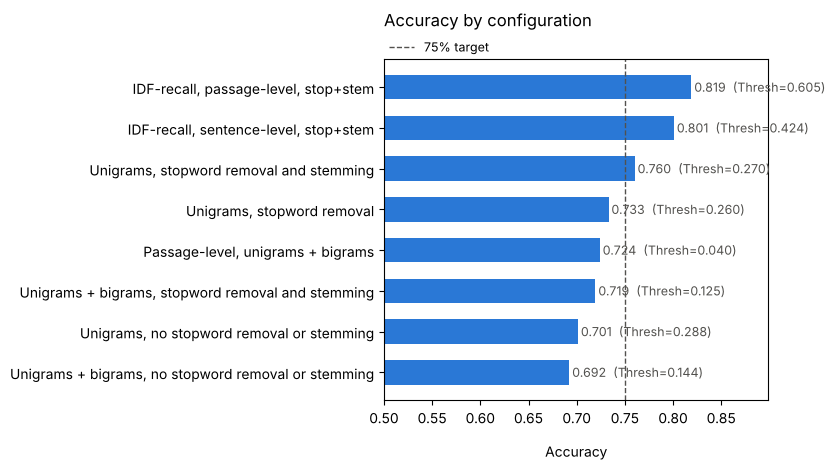

In [30]:
# Ablation accuracy per configuration (best threshold each)
ordered = sorted(ablation_results, key=lambda r: r["metrics"]["accuracy"])
names = [r["name"] for r in ordered]
accs = [r["metrics"]["accuracy"] for r in ordered]

# Prepare a horizontal bar chart to visualize the accuracy of each configuration.
fig, ax = plt.subplots(figsize=(8, 0.45 * len(ordered) + 1.2))
bars = ax.barh(names, accs, color=BLUE, height=0.6)
ax.axvline(TARGET, color=INK, linestyle="--", linewidth=1, label="75% target")

# Annotate each bar with its accuracy and threshold for clarity.
for bar, acc, r in zip(bars, accs, ordered):
    ax.text(acc + 0.003, bar.get_y() + bar.get_height() / 2,
            f"{acc:.3f}  (Thresh={r['metrics']['threshold']:.3f})",
            va="center", fontsize=9, color=INK)

# Set the x-axis limits, labels, title, and grid for better readability.
ax.set_xlim(0.5, max(accs) + 0.08)
ax.set_xlabel("Accuracy", labelpad=12)
ax.set_title("Accuracy by configuration", loc="left", pad=24)
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0),
          fontsize=9, borderaxespad=0)
fig.tight_layout()
fig.savefig(FIG_DIR / "ablation_accuracy.png", bbox_inches="tight")
plt.show()

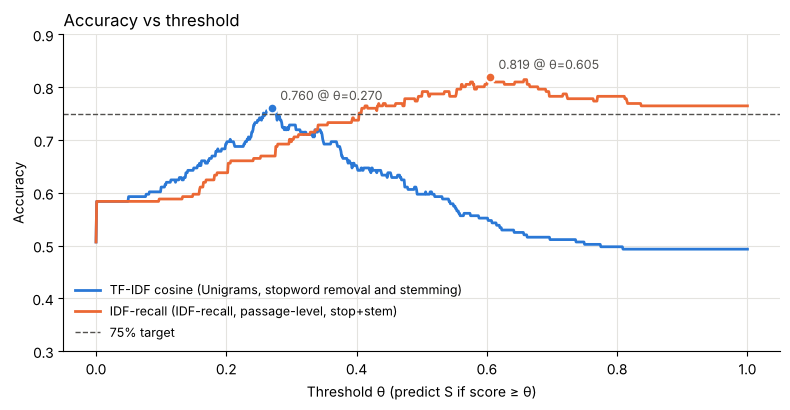

In [31]:
# Accuracy vs threshold: best cosine config vs best IDF-recall config.
# Shows why IDF-recall is more robust: a broad plateau instead of a sharp peak.
best_cosine = max(
    (r for r in ablation_results if r["config"].get("metric", "cosine") == "cosine"),
    key=lambda r: r["metrics"]["accuracy"],
)
best_recall = max(
    (r for r in ablation_results if r["config"].get("metric") == "idf_recall"),
    key=lambda r: r["metrics"]["accuracy"],
)

thresholds = np.linspace(0.0, 1.0, 1001)

fig, ax = plt.subplots(figsize=(8, 4.2))
for result, colour, label in [
    (best_cosine, BLUE, f"TF-IDF cosine ({best_cosine['name']})"),
    (best_recall, ORANGE, f"IDF-recall ({best_recall['name']})"),
]:
    # Accuracy at every threshold on the grid.
    curve = [((result["scores"] >= t).astype(int) == y_true).mean() for t in thresholds]
    ax.plot(thresholds, curve, color=colour, linewidth=2, label=label)

    # Mark the chosen (best) threshold.
    best_t = result["metrics"]["threshold"]
    best_a = result["metrics"]["accuracy"]
    ax.plot(best_t, best_a, "o", color=colour, markersize=7,
            markeredgecolor="white", markeredgewidth=1.5)
    ax.annotate(f"{best_a:.3f} @ θ={best_t:.3f}", (best_t, best_a),
                textcoords="offset points", xytext=(6, 6), fontsize=9, color=INK)

ax.axhline(TARGET, color=INK, linestyle="--", linewidth=1, label="75% target")
ax.set_xlabel("Threshold θ (predict S if score ≥ θ)")
ax.set_ylabel("Accuracy")
ax.set_ylim(0.3, 0.9)
ax.set_title("Accuracy vs threshold", loc="left")
ax.grid(color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "accuracy_vs_threshold.png", dpi=200, bbox_inches="tight")
plt.show()

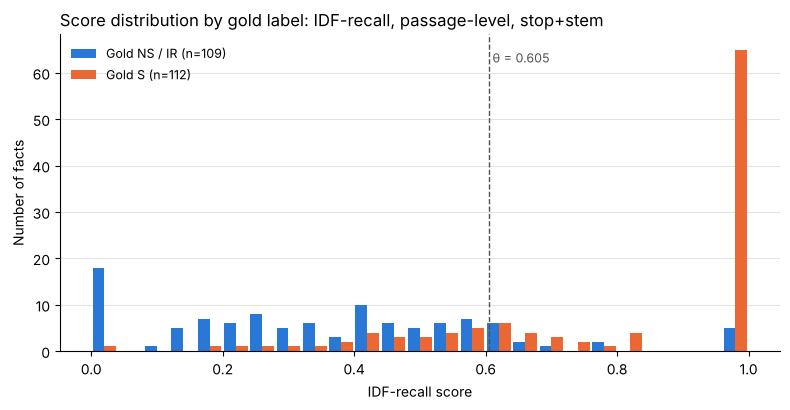

In [32]:
# Score distribution for S vs NS facts under the final configuration.
# Good separation = most S facts to the right of θ, most NS facts to the left.
best_overall = ablation_results[0]   # already sorted best-first
scores_best = best_overall["scores"]
best_t = best_overall["metrics"]["threshold"]
bins = np.linspace(0, 1, 26)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(
    [scores_best[y_true == 0], scores_best[y_true == 1]],
    bins=bins,
    color=[BLUE, ORANGE],
    label=[
        f"Gold NS / IR (n={int((y_true == 0).sum())})",
        f"Gold S (n={int((y_true == 1).sum())})",
    ],
    rwidth=0.9,
)
ax.axvline(best_t, color=INK, linestyle="--", linewidth=1)
ax.text(best_t, ax.get_ylim()[1] * 0.95, f" θ = {best_t:.3f}",
        color=INK, fontsize=9, va="top")

ax.set_xlabel("IDF-recall score")
ax.set_ylabel("Number of facts")
ax.set_title(f"Score distribution by gold label: {best_overall['name']}", loc="left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "score_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

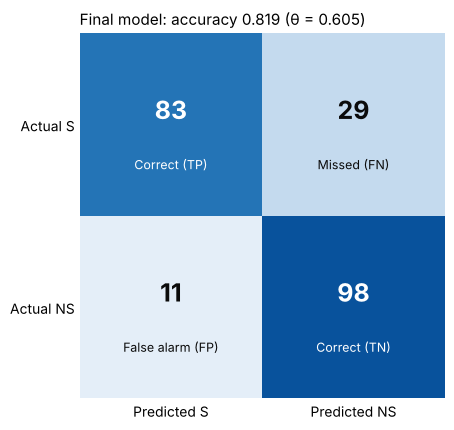

In [33]:
# Confusion matrix of the final model (same numbers as factchecking_main.py).
m = best_overall["metrics"]
matrix = np.array([
    [m["TP"], m["FN"]],   # actual S
    [m["FP"], m["TN"]],   # actual NS
])
cell_labels = [["Correct (TP)", "Missed (FN)"],
               ["False alarm (FP)", "Correct (TN)"]]

fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.imshow(matrix, cmap="Blues", vmin=0, vmax=matrix.max() * 1.15)

for i in range(2):
    for j in range(2):
        value = matrix[i, j]
        colour = "white" if value > matrix.max() * 0.55 else "#0b0b0b"
        ax.text(j, i - 0.08, str(value), ha="center", va="center",
                fontsize=18, fontweight="bold", color=colour)
        ax.text(j, i + 0.22, cell_labels[i][j], ha="center", va="center",
                fontsize=9, color=colour)

ax.set_xticks([0, 1], labels=["Predicted S", "Predicted NS"])
ax.set_yticks([0, 1], labels=["Actual S", "Actual NS"])
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title(f"Final model: accuracy {m['accuracy']:.3f} (θ = {m['threshold']:.3f})",
             loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

In [34]:
SEED = 42

1. **Accuracy by configuration:** summarises the ablation; the dashed line marks the 75% target.
2. **Accuracy vs threshold:** cosine peaks sharply at 0.760, so small changes in θ cost 2–6 points. IDF-recall stays above 75% from θ ≈ 0.40 to 1.0, so the choice of θ is robust.
3. **Score distribution:** most NS facts score below 0.6, and 65 S facts score exactly 1.0 (every content word found). The overlap region (0.4–0.7) is where errors happen.
4. **Confusion matrix:** the final model is conservative: only 11 false alarms but 29 missed supported facts, mostly paraphrases that word overlap can't match.

   ## 13. Further Tuning

   Two changes to IDF-recall, both using **no labels**:
   1. **Drop subject-name terms** (taken from the Wikipedia page title). Every passage comes from the subject's own page, so the name always matches and inflates the score of unsupported facts without carrying evidence.
   2. **Global IDF** estimated over all 1,562 unique passages in the retrieval corpus, instead of the 2–5 passages for each fact, giving more reliable rarity estimates.

   All 8 combinations (evidence unit × name removal × IDF source) are evaluated with the same grid search and 5-fold CV as before.

In [ ]:
# Global IDF: estimated once over every unique passage in the retrieval corpus.
# Uses only passage text (no labels), so it is not tuned on the gold answers.
unique_passages = {}
for record in passages_data:
    for passage in record.get("passages") or []:
        key = (passage.get("title", ""), get_passage_text(passage))
        unique_passages[key] = set(tokenize(get_passage_text(passage)))

global_df = Counter()
for terms in unique_passages.values():
    global_df.update(terms)

N_GLOBAL_DOCS = len(unique_passages)
GLOBAL_IDF = {
    term: log((N_GLOBAL_DOCS + 1) / (df + 1)) + 1.0
    for term, df in global_df.items()
}
UNSEEN_IDF = log(N_GLOBAL_DOCS + 1) + 1.0    # a term that appears in 0 documents

print(f"Global IDF built from {N_GLOBAL_DOCS} unique passages, {len(GLOBAL_IDF)} terms.")


def subject_name_terms(passages):
    """Tokens of the subject's name, taken from the Wikipedia page title.
    e.g. 'Fernando (footballer, born 1984)' -> {'fernando'}"""
    if not passages:
        return set()
    title = re.sub(r"\(.*?\)", " ", passages[0].get("title", ""))
    return set(tokenize(title))


def idf_recall_v2(fact, passages, sentence_level=True, drop_name=True, idf_source="global"):
    """
    IDF-weighted recall with two extra options:
      drop_name  : remove subject-name terms from the fact. Every retrieved passage is from
                   the subject's own page, so the name always matches and inflates the
                   score of unsupported facts without carrying any evidence.
      idf_source : "global" = IDF over the whole retrieval corpus (stable estimates);
                   "local"  = IDF over [fact] + this fact's evidence units (as before).
    """
    fact_terms = set(tokenize(fact))
    if drop_name:
        content_terms = fact_terms - subject_name_terms(passages)
        if content_terms:                  # keep the name if it's all the fact contains
            fact_terms = content_terms
    if not fact_terms:
        return 0.0

    # extract evidence units
    unit_term_sets = []
    for passage in passages or []:
        text = get_passage_text(passage)
        units = split_into_sentences(text) if sentence_level else [text]
        for unit in units:
            terms = set(tokenize(unit))
            if terms:
                unit_term_sets.append(terms)
    if not unit_term_sets:
        return 0.0

    # choose idf weights
    if idf_source == "global":
        weights = {t: GLOBAL_IDF.get(t, UNSEEN_IDF) for t in fact_terms}
    else:
        local_idf = compute_idf([list(fact_terms)] + [list(u) for u in unit_term_sets])
        weights = {t: local_idf[t] for t in fact_terms}

    # calculate weighted recall
    # the function calculates the recall score for every evidence unit and returns the highest score
    total = sum(weights.values())
    return float(max(sum(weights[t] for t in fact_terms & u) / total for u in unit_term_sets))

Global IDF built from 1562 unique passages, 18199 terms.


In [ ]:
# 2 x 2 x 2 ablation: evidence unit x subject-name removal x IDF source.
def cv_accuracy(scores, n_folds=5):
    """Held-out accuracy with θ re-tuned on each training split (same as Part 1 CV)."""
    rng = np.random.default_rng(SEED)
    indices = rng.permutation(len(y_true))
    accs = []
    for test_idx in np.array_split(indices, n_folds):
        train_idx = np.setdiff1d(indices, test_idx)
        best_train, _ = find_best_threshold(y_true[train_idx], scores[train_idx])
        accs.append(compute_metrics(y_true[test_idx], scores[test_idx], best_train["threshold"])["accuracy"])
    return float(np.mean(accs))


tuning_results = []
for sentence_level in [False, True]:
    for drop_name in [False, True]:
        for idf_source in ["local", "global"]:

            # calculate score for every fact
            scores = np.array([
                idf_recall_v2(ex["fact"], ex["passages"], sentence_level, drop_name, idf_source)
                for ex in examples
            ])
            best, _ = find_best_threshold(y_true, scores)
            tuning_results.append({
                "unit": "sentence" if sentence_level else "passage",
                "drop_name": drop_name,
                "idf": idf_source,
                "threshold": best["threshold"],
                "accuracy": best["accuracy"],
                "f1": best["f1"],
                "cv_accuracy": cv_accuracy(scores),
                "scores": scores,
            })

tuning_results.sort(key=lambda r: (r["accuracy"], r["cv_accuracy"]), reverse=True)

print(f"{'Unit':<10}{'Drop name':<11}{'IDF':<8}{'θ':>7}{'Accuracy':>10}{'CV acc':>9}{'F1':>8}")
for r in tuning_results:
    print(f"{r['unit']:<10}{str(r['drop_name']):<11}{r['idf']:<8}"
          f"{r['threshold']:>7.3f}{r['accuracy']:>10.4f}{r['cv_accuracy']:>9.4f}{r['f1']:>8.4f}")

Unit      Drop name  IDF           θ  Accuracy   CV acc      F1
sentence  True       global    0.455    0.8778   0.8687  0.8789
passage   True       global    0.455    0.8552   0.8370  0.8621
sentence  True       local     0.468    0.8462   0.8187  0.8381
passage   True       local     0.441    0.8462   0.8143  0.8468
passage   False      global    0.718    0.8281   0.8007  0.8224
passage   False      local     0.605    0.8190   0.7965  0.8058
sentence  False      local     0.424    0.8009   0.7557  0.8151
sentence  False      global    0.494    0.7919   0.7513  0.8099


In [ ]:
# Best tuned configuration vs the previous final model.
tuned = tuning_results[0]
tuned_scores = tuned["scores"]

# get its best threshold and evaluation metrics
tuned_best, _ = find_best_threshold(y_true, tuned_scores)

# 
tuned_pred = (tuned_scores >= tuned_best["threshold"]).astype(int)

old_scores = ablation_results[0]["scores"]                 # IDF-recall, passage, local IDF (81.9%)
old_pred = (old_scores >= ablation_results[0]["metrics"]["threshold"]).astype(int)

print(f"Tuned: {tuned['unit']}, drop_name={tuned['drop_name']}, idf={tuned['idf']}")
print(f"θ = {tuned_best['threshold']:.3f}  accuracy = {tuned_best['accuracy']:.4f}  "
      f"(previous: {ablation_results[0]['metrics']['accuracy']:.4f})")
print({k: tuned_best[k] for k in ["TP", "FN", "FP", "TN"]})

# Threshold sensitivity.
grid = np.linspace(0, 1, 1001)

# calculate accuracy for every threshold
accs = np.array([compute_metrics(y_true, tuned_scores, t)["accuracy"] for t in grid])

# then find ranges greater than 85%
print(f"Accuracy ≥ 85% for θ in [{grid[accs >= 0.85].min():.3f}, {grid[accs >= 0.85].max():.3f}]")

fixed = int(((tuned_pred == y_true) & (old_pred != y_true)).sum())
broke = int(((tuned_pred != y_true) & (old_pred == y_true)).sum())
print(f"\nvs previous model: fixed {fixed} errors, introduced {broke}")

Tuned: sentence, drop_name=True, idf=global
θ = 0.455  accuracy = 0.8778  (previous: 0.8190)
{'TP': 98, 'FN': 14, 'FP': 13, 'TN': 96}
Accuracy ≥ 85% for θ in [0.430, 0.526]

vs previous model: fixed 21 errors, introduced 8


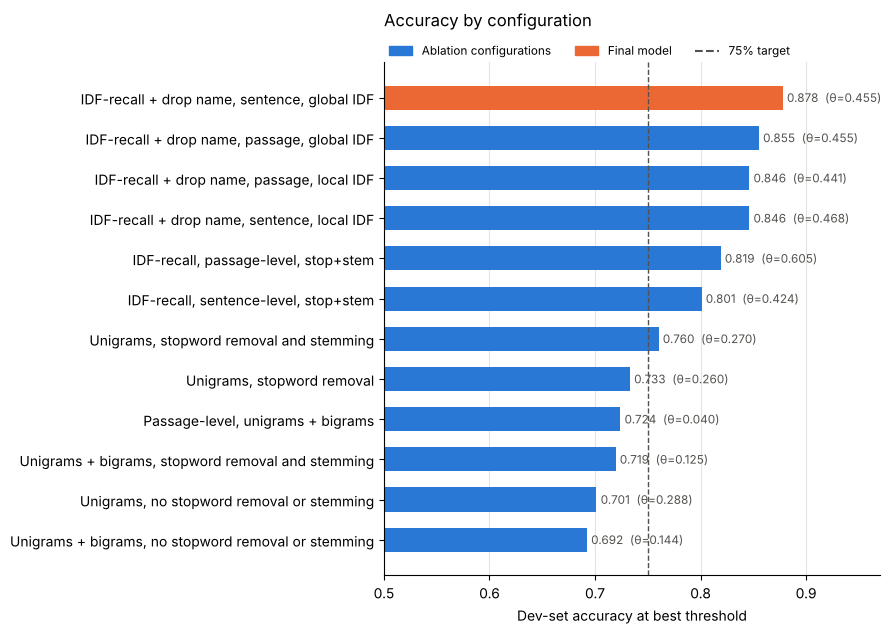

In [38]:
# Updated figures for the final (tuned) model

FIG_DIR.mkdir(exist_ok=True)
GREEN = "#1baf7a"   # third series colour (final model)

final_theta = tuned_best["threshold"]
final_acc = tuned_best["accuracy"]

# Figure 1: accuracy by configuration
bars_data = [(r["name"], r["metrics"]["accuracy"], r["metrics"]["threshold"], False)
             for r in ablation_results]
for r in tuning_results:
    if r["drop_name"]:   # the new variants; the others duplicate rows already in the ablation
        label = f"IDF-recall + drop name, {r['unit']}, {r['idf']} IDF"
        bars_data.append((label, r["accuracy"], r["threshold"], r is tuning_results[0]))
bars_data.sort(key=lambda b: b[1])

fig, ax = plt.subplots(figsize=(9, 0.42 * len(bars_data) + 1.4))
colours = [ORANGE if b[3] else BLUE for b in bars_data]
bars = ax.barh([b[0] for b in bars_data], [b[1] for b in bars_data], color=colours, height=0.6)
ax.axvline(TARGET, color=INK, linestyle="--", linewidth=1)
for bar, (_, acc, theta, _) in zip(bars, bars_data):
    ax.text(acc + 0.004, bar.get_y() + bar.get_height() / 2,
            f"{acc:.3f}  (θ={theta:.3f})", va="center", fontsize=8.5, color=INK)
ax.set_xlim(0.5, 0.97)
ax.set_xlabel("Dev-set accuracy at best threshold")
ax.set_title("Accuracy by configuration", loc="left", pad=26)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(handles=[Patch(color=BLUE, label="Ablation configurations"),
                   Patch(color=ORANGE, label="Final model"),
                   Line2D([0], [0], color=INK, linestyle="--", label="75% target")],
          frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, fontsize=8.5, borderaxespad=0)
fig.tight_layout()
fig.savefig(FIG_DIR / "ablation_accuracy.png", dpi=200, bbox_inches="tight")
plt.show()

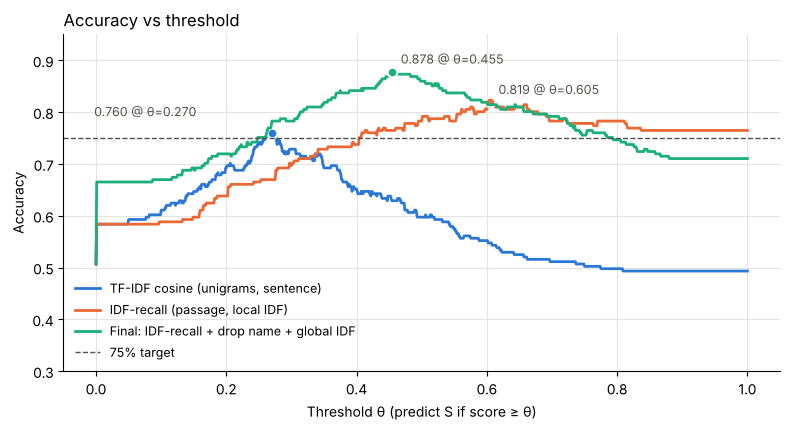

In [39]:
# Figure 2: accuracy vs threshold (best cosine, original IDF-recall, final)
best_cosine = max((r for r in ablation_results if r["config"].get("metric", "cosine") == "cosine"),
                  key=lambda r: r["metrics"]["accuracy"])
best_recall = max((r for r in ablation_results if r["config"].get("metric") == "idf_recall"),
                  key=lambda r: r["metrics"]["accuracy"])
curves = [
    (best_cosine["scores"], best_cosine["metrics"]["threshold"], best_cosine["metrics"]["accuracy"],
     BLUE, "TF-IDF cosine (unigrams, sentence)", (-128, 12)),
    (best_recall["scores"], best_recall["metrics"]["threshold"], best_recall["metrics"]["accuracy"],
     ORANGE, "IDF-recall (passage, local IDF)", (6, 6)),
    (tuned_scores, final_theta, final_acc, GREEN, "Final: IDF-recall + drop name + global IDF", (6, 6)),
]
grid = np.linspace(0.0, 1.0, 1001)
fig, ax = plt.subplots(figsize=(8, 4.4))
for scores, theta, acc, colour, label, offset in curves:
    curve = [((scores >= t).astype(int) == y_true).mean() for t in grid]
    ax.plot(grid, curve, color=colour, linewidth=2, label=label)
    ax.plot(theta, acc, "o", color=colour, markersize=7, markeredgecolor="white", markeredgewidth=1.5)
    ax.annotate(f"{acc:.3f} @ θ={theta:.3f}", (theta, acc), textcoords="offset points",
                xytext=offset, fontsize=9, color=INK)
ax.axhline(TARGET, color=INK, linestyle="--", linewidth=1, label="75% target")
ax.set_xlabel("Threshold θ (predict S if score ≥ θ)")
ax.set_ylabel("Accuracy")
ax.set_ylim(0.3, 0.95)
ax.set_title("Accuracy vs threshold", loc="left")
ax.grid(color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "accuracy_vs_threshold.png", dpi=200, bbox_inches="tight")
plt.show()

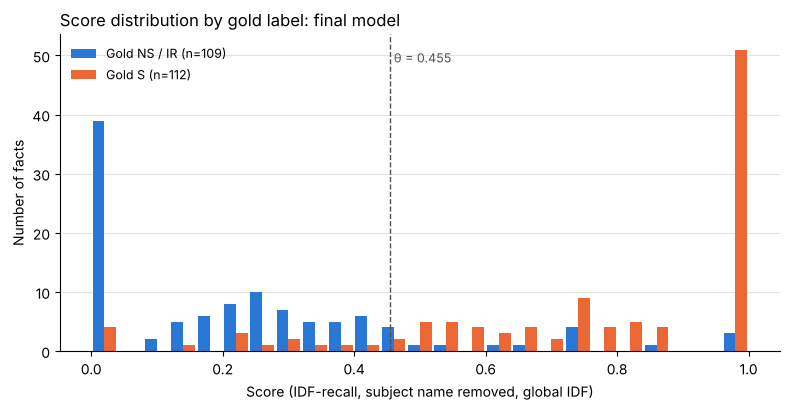

In [40]:
# Figure 3: score distribution for the final model
bins = np.linspace(0, 1, 26)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist([tuned_scores[y_true == 0], tuned_scores[y_true == 1]], bins=bins, color=[BLUE, ORANGE],
        label=[f"Gold NS / IR (n={int((y_true == 0).sum())})", f"Gold S (n={int((y_true == 1).sum())})"],
        rwidth=0.9)
ax.axvline(final_theta, color=INK, linestyle="--", linewidth=1)
ax.text(final_theta, ax.get_ylim()[1] * 0.95, f" θ = {final_theta:.3f}", color=INK, fontsize=9, va="top")
ax.set_xlabel("Score (IDF-recall, subject name removed, global IDF)")
ax.set_ylabel("Number of facts")
ax.set_title("Score distribution by gold label: final model", loc="left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "score_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

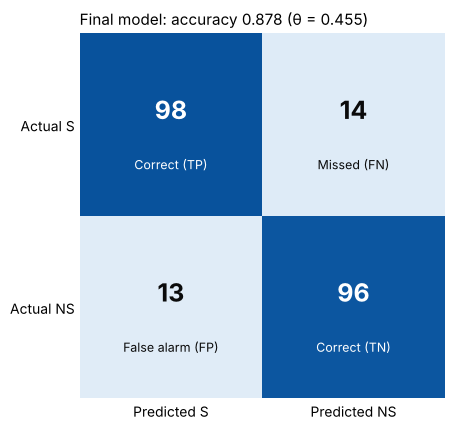

In [41]:
# Figure 4: confusion matrix for the final model
m = tuned_best
matrix = np.array([[m["TP"], m["FN"]], [m["FP"], m["TN"]]])
cell_labels = [["Correct (TP)", "Missed (FN)"], ["False alarm (FP)", "Correct (TN)"]]
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.imshow(matrix, cmap="Blues", vmin=0, vmax=matrix.max() * 1.15)
for i in range(2):
    for j in range(2):
        colour = "white" if matrix[i, j] > matrix.max() * 0.55 else "#0b0b0b"
        ax.text(j, i - 0.08, str(matrix[i, j]), ha="center", va="center", fontsize=18,
                fontweight="bold", color=colour)
        ax.text(j, i + 0.22, cell_labels[i][j], ha="center", va="center", fontsize=9, color=colour)
ax.set_xticks([0, 1], labels=["Predicted S", "Predicted NS"])
ax.set_yticks([0, 1], labels=["Actual S", "Actual NS"])
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title(f"Final model: accuracy {final_acc:.3f} (θ = {final_theta:.3f})", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

**Figures (final model)**

1. **Accuracy by configuration:** compares every configuration tested in the ablation study and Section 13. The final model (orange) achieves the highest accuracy at 87.8%.
2. **Accuracy vs threshold:** the final model (green) outperforms both earlier models across most thresholds. Its accuracy stays above 80% for θ between 0.31 and 0.67, and above 75% for θ between 0.25 and 0.79, so the result does not depend on one exact threshold.
3. **Score distribution:** supported and unsupported facts are now much more clearly separated. 39 unsupported facts score close to 0 (up from 18), because removing the subject's name means they no longer get free overlap from it. 51 supported facts still score a perfect 1.0.
4. **Confusion matrix:** 98 true positives, 14 false negatives, 13 false positives and 96 true negatives. Compared with the earlier model, missed supported facts fall from 29 to 14, while false alarms stay roughly the same (11 to 13).

In [42]:
# Original ablation (Section 11) -> ablation_results.csv
with open("ablation_results.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["configuration", "metric", "unit", "ngram_range", "remove_stop", "stem",
                     "threshold", "accuracy", "precision", "recall", "f1", "TP", "TN", "FP", "FN"])
    for r in ablation_results:
        c, m = r["config"], r["metrics"]
        writer.writerow([r["name"], c.get("metric", "cosine"),
                         "sentence" if c["sentence_level"] else "passage", c["ngram_range"],
                         c["remove_stop"], c["stem"], f"{m['threshold']:.3f}", f"{m['accuracy']:.4f}",
                         f"{m['precision']:.4f}", f"{m['recall']:.4f}", f"{m['f1']:.4f}",
                         m["TP"], m["TN"], m["FP"], m["FN"]])

# Further tuning -> tuning_results.csv
with open("tuning_results.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["unit", "drop_name", "idf", "threshold", "accuracy", "cv_accuracy",
                     "precision", "recall", "f1", "TP", "TN", "FP", "FN", "is_final"])
    for r in tuning_results:
        m = compute_metrics(y_true, r["scores"], r["threshold"])
        writer.writerow([r["unit"], r["drop_name"], r["idf"], f"{r['threshold']:.3f}",
                         f"{r['accuracy']:.4f}", f"{r['cv_accuracy']:.4f}", f"{m['precision']:.4f}",
                         f"{m['recall']:.4f}", f"{m['f1']:.4f}", m["TP"], m["TN"], m["FP"], m["FN"],
                         int(r is tuning_results[0])])

print("Saved ablation_results.csv (8 rows) and tuning_results.csv (8 rows)")

Saved ablation_results.csv (8 rows) and tuning_results.csv (8 rows)


In [43]:
print(classification_report(y_true, tuned_pred, target_names=["NS", "S"], digits=4))

              precision    recall  f1-score   support

          NS     0.8727    0.8807    0.8767       109
           S     0.8829    0.8750    0.8789       112

    accuracy                         0.8778       221
   macro avg     0.8778    0.8779    0.8778       221
weighted avg     0.8779    0.8778    0.8778       221



## 14. Evidence for the Report

Prints the values used in the report: the Figure 2 example, preprocessing examples and the claims about fact length and subject names.

In [44]:
# for Figure 2 example: trace one fact through the final scorer
import sys, re
sys.path.insert(0, "../..")
from factcheck import WordRecallThresholdFactChecker

checker = WordRecallThresholdFactChecker(passages_path="../../data/passages_bm25_ChatGPT_humfacts.jsonl")
fact = "Marianne McAndrew was born in Cleveland."
passages = next(r["passages"] for r in passages_data if r["sent"] == fact)

tokens = checker.tokenize(fact)
title_tokens = checker.tokenize(re.sub(r"\(.*?\)", " ", passages[0]["title"]))
content = set(tokens) - set(title_tokens)

print("Tokens:", tokens)
print("Title tokens removed:", title_tokens)
print("Remaining terms:", content)
for t in tokens:
    print(f"  idf({t}) = {checker.idf(t):.2f}")
print("Score:", round(checker.score(fact, passages), 3), "->", checker.predict(fact, passages))

Tokens: ['mariann', 'mcandrew', 'born', 'cleveland']
Title tokens removed: ['mariann', 'mcandrew']
Remaining terms: {'cleveland', 'born'}
  idf(mariann) = 7.26
  idf(mcandrew) = 7.26
  idf(born) = 2.92
  idf(cleveland) = 6.16
Score: 0.0 -> NS


In [45]:
# Preprocessing evidence: stemming, negation and digits
for text in ["acting", "acted", "Marianne did not win in 1942."]:
    print(repr(text), "->", checker.tokenize(text))

'acting' -> ['act']
'acted' -> ['act']
'Marianne did not win in 1942.' -> ['mariann', 'not', 'win', '1942']


In [46]:
import numpy as np, re

# "Facts are only 5-10 words long" (Part 1 findings)
lengths = [len(ex["fact"].split()) for ex in examples]
print(f"Fact length: mean {np.mean(lengths):.1f}, median {np.median(lengths):.0f}, "
      f"{np.mean([5 <= n <= 10 for n in lengths]):.0%} have 5-10 words")

# "The subject's name appears in almost every passage" (name removal)
total = with_name = 0
for ex in examples:
    if not ex["passages"]:
        continue
    name = set(checker.tokenize(re.sub(r"\(.*?\)", " ", ex["passages"][0]["title"])))
    for p in ex["passages"]:
        total += 1
        with_name += bool(name & set(checker.tokenize(p["text"])))
print(f"Passages containing the subject's name: {with_name}/{total}")

Fact length: mean 6.8, median 7, 80% have 5-10 words


Passages containing the subject's name: 603/692
